# Explore a GRS L2B datacube

This notebook walks through a time series of GRS **L2B** products (water-quality parameters retrieved
from the L2A remote sensing reflectance) over the Berre lagoon (France), around the HYPERNETS station
`BEFR`:

1. build a multi-temporal `xarray` datacube of the L2B products with `grstbx.L2grs`, cropped to a box
   centred on the station;
2. mask the non-water / cloudy pixels and discard the images with too few valid pixels;
3. explore the datacube interactively: map of each parameter and date, time series of the pixel under
   the mouse and of drawn points, statistics over drawn polygons;
4. map the parameters over one month and as monthly composites.

**Input:** GRS L2B products (netCDF) stored as `<L2B_DIR>/<SITE>/YYYY/MM/DD/<product>.nc`, here the
Sentinel-2 A/B subsets (20 m) of the BEFR site processed with GRS v2.2.1.

**Interactive cells:** section 3 uses a `panel`/`holoviews` viewer. Draw on the map, then run the
following cells. Default points (`DEFAULT_POI`) and a default polygon (`DEFAULT_AOI`) around the station
are preloaded on the map, so that the time series and the polygon statistics are computed even when
nothing is drawn (e.g. in the online documentation, where the widgets are not interactive).

## 1. Libraries

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
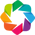

grstbx: 2.3.1


In [1]:
import glob
import os

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rioxarray  # activate the .rio accessor
import matplotlib.pyplot as plt
import panel as pn

import grstbx
from grstbx import visual

pn.extension()
opj = os.path.join

print(f'grstbx: {grstbx.__version__}')

## 2. Select and load the products

Configuration of the site, period and box of the datacube:

- `CLON`, `CLAT`: centre of the box (here the BEFR station), `BOX_SIZE`: side of the square box (m);
- `VARIABLES`: L2B variables kept in the datacube (the other ones are dropped to save memory);
- `DATACUBE_DIR`: folder where the datacube is cached as a netCDF file, since reading a year of
  products takes a while (delete the cached file to rebuild it).

In [2]:
SITE = 'BEFR'
CLON, CLAT = 5.0972, 43.4423   # BEFR station
L2B_DIR = '/data/satellite/Sentinel-2/subset/hypernets/L2B_v221'
DATACUBE_DIR = '/data/satellite/Sentinel-2/subset/datacube'
START_DATE, END_DATE = '2024-01-01', '2024-12-31'
BOX_SIZE = 8000   # m

VARIABLES = ['Chla_OC2nasa', 'Chla_M09B', 'SPM_nechad', 'SPM_obs2co', 'TURB_dogliotti',
             'acdom_B15', 'Kd_par', 'owt_index_Bi2024', 'mask']

The product names follow the ESA convention
`<satellite>_<level>_<time>_<baseline>_<orbit>_<tile>_<processing time>`: they are parsed into a table
of the products, indexed by acquisition time.

In [3]:
def list_grs_products(rootdir, site, pattern='*'):
    '''
    List the GRS products stored as ``rootdir/site/YYYY/MM/DD/<product>``.

    :return: pandas.DataFrame indexed (and sorted) by acquisition time, with the path of each product
    '''
    paths = sorted(glob.glob(opj(rootdir, site, '*', '*', '*', pattern)))
    if not paths:
        raise FileNotFoundError(f'no product found in {opj(rootdir, site)}')
    names = pd.Series([os.path.basename(p) for p in paths])
    products = names.str.split('_', expand=True).iloc[:, :7]
    products.columns = ['satellite', 'level', 'time', 'baseline', 'orbit', 'tile', 'processing_time']
    products['time'] = pd.to_datetime(products['time'])
    products['path'] = paths
    return products.set_index('time').sort_index()


products = list_grs_products(L2B_DIR, SITE)[START_DATE:END_DATE]
print(f'{len(products)} L2B products from {START_DATE} to {END_DATE}')
products.head()

95 L2B products from 2024-01-01 to 2024-12-31


,satellite,level,baseline,orbit,tile,processing_time,path
time,,,,,,,
2024-01-04 10:34:31,S2A,MSIL2B,N0510,R108,T31TFJ,20240104T123149.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...
2024-01-09 10:33:29,S2B,MSIL2B,N0510,R108,T31TFJ,20240109T112201.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...
2024-01-12 10:43:19,S2B,MSIL2B,N0510,R008,T31TFJ,20240112T214056.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...
2024-01-24 10:33:21,S2A,MSIL2B,N0510,R108,T31TFJ,20240124T123418.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...
2024-02-03 10:32:31,S2A,MSIL2B,N0510,R108,T31TFJ,20240203T123412.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...


`L2grs.get_l2b_datacube` reads the products cropped to the box (`subset`) in parallel and stacks them
along a `time` dimension; images without any valid pixel are skipped.

In [4]:
box = grstbx.SpatioTemp().wktbox(CLON, CLAT, width=BOX_SIZE, height=BOX_SIZE)
bbox = gpd.GeoDataFrame(geometry=gpd.GeoSeries.from_wkt([box]), crs=4326)

os.makedirs(DATACUBE_DIR, exist_ok=True)
dc_path = opj(DATACUBE_DIR, f'{SITE}_{START_DATE}_{END_DATE}_box{BOX_SIZE}m.nc')
if not os.path.exists(dc_path):
    dc = grstbx.L2grs(products.path.values)
    dc.get_l2b_datacube(subset=bbox)
    # times stored in seconds (by default, xarray may truncate them to days)
    dc.datacube[VARIABLES].to_netcdf(dc_path, encoding={'time': {'units': 'seconds since 1970-01-01',
                                                                 'dtype': 'int64'}})

dcube = xr.open_dataset(dc_path, decode_coords='all').drop_duplicates('time').load()
crs = dcube.rio.crs
dcube

<xarray.Dataset>
Dimensions:           (time: 95, y: 409, x: 409)
Coordinates:
  * time              (time) datetime64[ns] 2024-01-04T10:34:31 ... 2024-12-2...
  * x                 (x) float64 6.656e+05 6.656e+05 ... 6.738e+05 6.738e+05
    band              int64 1
    spatial_ref       int64 0
  * y                 (y) float64 4.816e+06 4.816e+06 ... 4.808e+06 4.808e+06
Data variables:
    Chla_OC2nasa      (time, y, x) float32 1.59 1.681 1.754 ... 3.106 2.869
    Chla_M09B         (time, y, x) float32 27.46 22.66 6.884 ... 27.48 13.62 nan
    SPM_nechad        (time, y, x) float32 17.51 17.99 17.72 ... 6.361 7.724
    SPM_obs2co        (time, y, x) float32 30.01 30.81 30.38 ... 11.2 13.58
    TURB_dogliotti    (time, y, x) float32 12.3 12.64 12.46 ... 4.324 5.268
    acdom_B15         (time, y, x) float32 3.406 3.287 3.395 ... nan 1.271 1.466
    Kd_par            (time, y, x) float32 1.433 1.425 1.525 ... 2.123 2.186
    owt_index_Bi2024  (time, y, x) float32 5.0 5.0 5.0 5.0 ... 6.0 6.0 6.0 5.0
    mask              (time, y, x) uint8 1 1 1 1 1 1 1 1 1 ... 0 0 0 0 0 0 0 0 0
Attributes: (12/75)
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/31TFJ...
    product_name:                        S2A_MSIL1C_20240104T103431_N0510_R10...
    product_filename:                    S2A_MSIL1C_20240104T103431_N0510_R10...
    ...                                  ...
    dirdata:                             /data/grs/grsdata
    abs_gas_file:                        /home/harmel/Dropbox/Dropbox/work/gi...
    water_vapor_transmittance_file:      /home/harmel/Dropbox/Dropbox/work/gi...
    metadata_profile:                    datacube
    start_date:                          2024-01-04T10:34:31.000000000
    stop_date:                           2024-12-29T10:34:41.000000000

### 2.1 Valid pixels

The L2B parameters are computed for all the pixels: the `mask` variable gives the good water pixels
(`mask == 0`), the other ones are flagged as land, cloud, cirrus, glint... (see the `flags` variable of
the products). The water pixels of the box are those valid in at least half of the images; for each
image, the proportion of valid water pixels measures the cloud cover of the box, and the images with
less than `MIN_VALID` valid pixels are discarded.

80 images kept out of 95


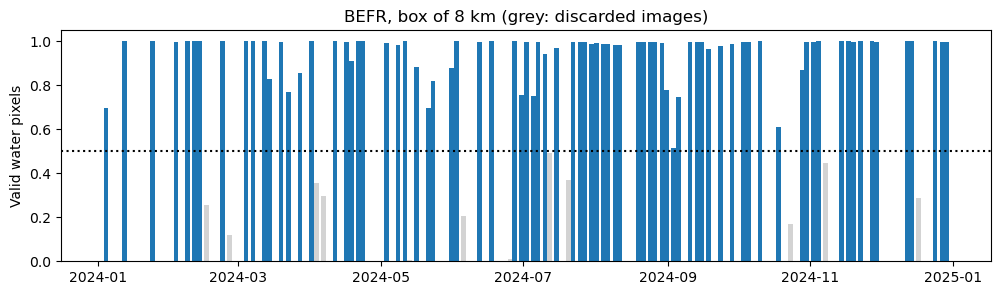

In [5]:
MIN_VALID = 0.5

valid = dcube['mask'] == 0
water = valid.mean('time') >= 0.5
valid_prop = valid.where(water).mean(['x', 'y']).to_series()

wq = dcube.drop_vars('mask').where(valid)
wq = wq.sel(time=valid_prop.index[valid_prop >= MIN_VALID])
print(f'{wq.sizes["time"]} images kept out of {dcube.sizes["time"]}')

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(valid_prop.index, valid_prop.values, width=2,
       color=np.where(valid_prop >= MIN_VALID, 'tab:blue', 'lightgrey'))
ax.axhline(MIN_VALID, color='k', ls=':')
ax.set_ylabel('Valid water pixels')
ax.set_title(f'{SITE}, box of {BOX_SIZE / 1000:g} km (grey: discarded images)');

## 3. Interactive exploration

`ViewParam` displays each 2D variable of the datacube over a basemap (`reproject=True`: the visible
window is reprojected to web Mercator, EPSG:3857). Only the pixels visible on the screen are read, at
the screen resolution.

Widgets:

- **Parameter** and **Date** of the map;
- **Basemap**: free basemaps (CARTO, OpenStreetMap, OpenTopoMap, Esri, Stamen / Stadia Maps, see
  `visual.BASEMAPS`), the initial one is set with `basemap=`;
- **Live time series**: full-resolution time series of the parameter at the pixel under the mouse,
  plotted live (dashed black line) in the panel beneath the map, where the date displayed on the map is
  marked by a vertical line; untick it to stop reading the data when hovering;
- **Range slider** and **Opacity** of the map;
- **Colormap** (with previews), **Reverse** and **Log scale**: sequential, perceptually uniform
  colormaps named after the water feature they enhance (`visual.RRS_COLORMAPS`); the initial one is set
  with `cmap=` (here cmocean *algae* for the chlorophyll-a).

Use the toolbar to:

- **Point Draw** tool: click to add points of interest (POI), their full-resolution time series are
  plotted with the live one; the points get colours automatically (in the drawing order), matching
  their time series;
- **Polygon Draw** tool: double-click to start a polygon, click to add vertices, double-click to close it
  (areas of interest, AOI).

The points given with `poi=` (here `DEFAULT_POI`, (lon, lat) tuples) and the polygons given with `aoi=`
(here `DEFAULT_AOI`, a WKT string in lon/lat; GeoDataFrames, shapely geometries and WKT strings are
accepted for both) are displayed on the map at start-up: they can be moved, edited or deleted like the
drawn ones. Then run the next cells: they read the geometries with `viewer.get_points()` and
`viewer.get_geom()`.

In [6]:
# default points and area of interest, preloaded on the map: used by the next cells when nothing is
# drawn (e.g. in the online documentation, where the widgets are not interactive)
DEFAULT_POI = [(CLON, CLAT),         # BEFR station
               (5.0646, 43.4693),    # north-west
               (5.1319, 43.45),      # east
               (5.0751, 43.4151)]    # south
DEFAULT_AOI = 'POLYGON ((5.0845 43.4335, 5.1092 43.4331, 5.1099 43.4511, 5.0852 43.4515, 5.0845 43.4335))'

viewer = visual.ViewParam(wq, params=['Chla_OC2nasa', 'Chla_M09B', 'SPM_nechad', 'SPM_obs2co',
                                      'TURB_dogliotti', 'acdom_B15', 'Kd_par', 'owt_index_Bi2024'],
                          reproject=True, minmaxvalues=(0, 10), minmax=(0, 50), cmap='cmo.algae',
                          aoi=DEFAULT_AOI, poi=DEFAULT_POI)
viewer.visu()

Column
    [0] WidgetBox
        [0] Markdown(str)
        [1] Column
            [0] Row
                [0] Row
                    [0] Markdown(str)
                    [1] Select(options=['Chla_OC2nasa', ...], value='Chla_OC2nasa')
                [1] Row
                    [0] Markdown(str)
                    [1] Select(options={'2024-01-04 10:34:31': 0,...}, value=0)
                [2] Row
                    [0] Markdown(str)
                    [1] Select(options=['CARTO Positron', ...], value='CARTO Positron')
                [3] Checkbox(name='Live time series', value=True)
            [1] Row
                [0] EditableRangeSlider(end=50, name='Range Slider', step=0.0001, value=(0, 10), width=300)
                [1] Row
                    [0] Markdown(str)
                    [1] FloatSlider(name='Opacity', step=0.05, value=0.95)
                [2] Row
                    [0] Markdown(str)
                    [1] ColorMap(options={'Rainbow (CET_R1)': ['#00...}, swatch_width=120, value=['#d7f9d0', '#d6f8ce', ...], value_name='Algae, chlorophyll (..., width=260)
                    [2] Column
                        [0] Checkbox(name='Reverse')
                        [1] Checkbox(name='Log scale')
    [1] HoloViews(DynamicMap, height=700, sizing_mode='fixed', width=1000)
    [2] HoloViews(DynamicMap, height=350, sizing_mode='fixed', width=1000)

### 3.1 Time series of the points

Time series of the points of the map (`DEFAULT_POI` and the drawn ones), with the colours of the map,
for the parameters of `PARAMS` (parameter: label of the axis).

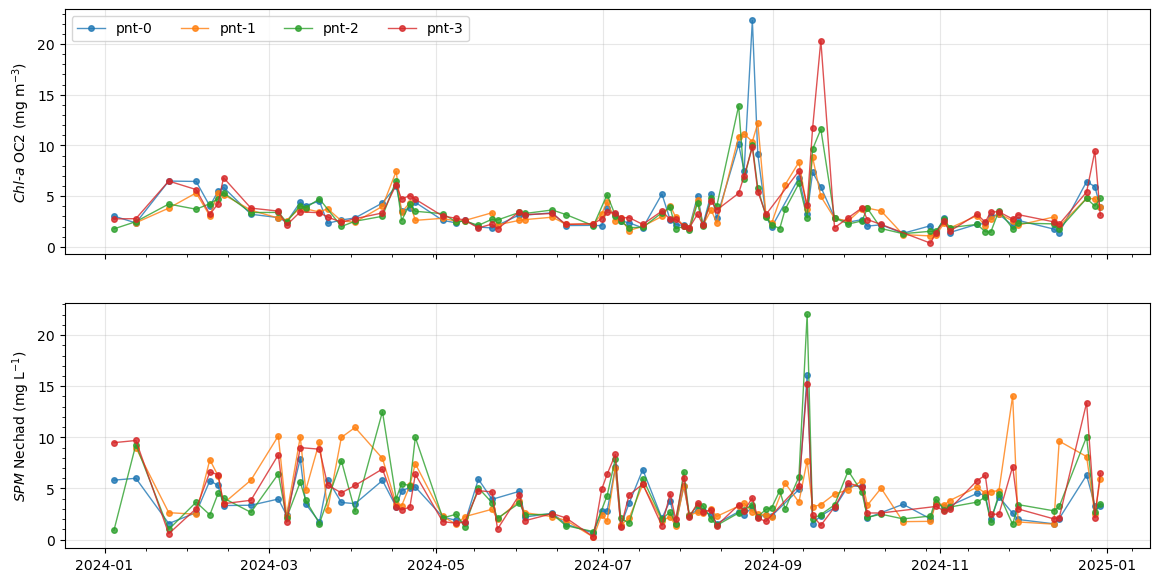

In [7]:
PARAMS = {'Chla_OC2nasa': r'$Chl$-$a$ OC2 (mg m$^{-3}$)',
          'SPM_nechad': r'$SPM$ Nechad (mg L$^{-1}$)'}

points = viewer.get_points(crs=crs)
if points.empty:
    print('No point: add points with the Point Draw tool and rerun this cell.')
else:
    fig, axs = plt.subplots(len(PARAMS), 1, figsize=(14, 3.5 * len(PARAMS)), sharex=True)
    for ax, (param, label) in zip(np.atleast_1d(axs), PARAMS.items()):
        for ii, (pt, color) in enumerate(zip(points.geometry, points['color'])):
            series = wq[param].sel(x=pt.x, y=pt.y, method='nearest').to_series().dropna()
            ax.plot(series.index, series.values, marker='o', ms=4, lw=1, c=color, alpha=0.8,
                    label=f'pnt-{ii}')
        ax.set_ylabel(label)
        ax.minorticks_on()
        ax.grid(alpha=0.3)
    np.atleast_1d(axs)[0].legend(ncol=len(points), fontsize=10)

### 3.2 Statistics over the polygons

For each polygon (the default `DEFAULT_AOI` and the drawn ones): time series of the median and of the
inter-quartile range (25–75 %) of the parameters over the valid pixels of the polygon. Images with less
than `MIN_VALID` valid pixels in the polygon are discarded.

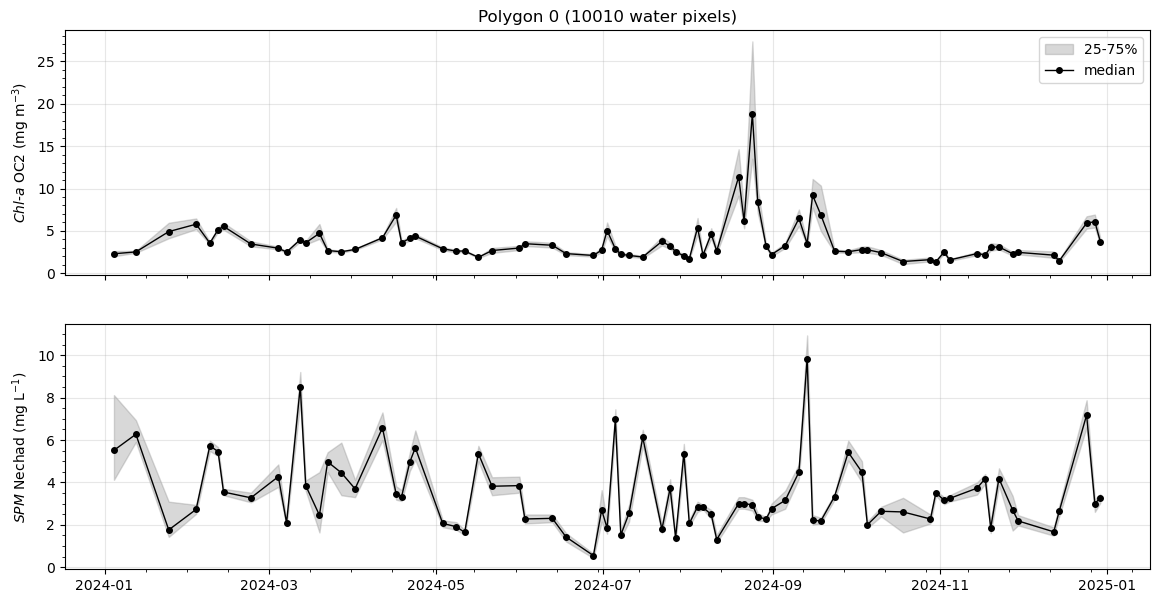

In [8]:
def aoi_stats(da, dim='gridcell'):
    '''Statistics of the valid pixels of a (time, y, x) DataArray, per date.'''
    stacked = da.stack({dim: ['y', 'x']})
    return xr.Dataset({
        'median': stacked.median(dim),
        'q25': stacked.quantile(0.25, dim=dim).drop_vars('quantile'),
        'q75': stacked.quantile(0.75, dim=dim).drop_vars('quantile'),
        'valid_prop': stacked.count(dim) / stacked.sizes[dim],
    }).to_dataframe()


n_poly = len(viewer.aoi_stream.data.get('xs', [])) if viewer.aoi_stream.data else 0
if n_poly == 0:
    print('No polygon: draw polygons with the Polygon Draw tool and rerun this cell.')
for index in range(n_poly):
    aoi = viewer.get_geom(crs=crs, index=index)
    clipped = wq.rio.clip(aoi.geometry.values)
    fig, axs = plt.subplots(len(PARAMS), 1, figsize=(14, 3.5 * len(PARAMS)), sharex=True)
    for ax, (param, label) in zip(np.atleast_1d(axs), PARAMS.items()):
        stats = aoi_stats(clipped[param])
        stats = stats[stats.valid_prop >= MIN_VALID]
        ax.fill_between(stats.index, stats.q25, stats.q75, color='grey', alpha=0.3, label='25-75%')
        ax.plot(stats.index, stats['median'], c='k', marker='o', ms=4, lw=1, label='median')
        ax.set_ylabel(label)
        ax.minorticks_on()
        ax.grid(alpha=0.3)
    np.atleast_1d(axs)[0].legend()
    n_pix = int(clipped[param].notnull().any('time').sum())
    np.atleast_1d(axs)[0].set_title(f'Polygon {index} ({n_pix} water pixels)')
    plt.show()

## 4. Maps

### 4.1 Images of one month

All the valid images of `MONTH` for the parameter `PARAM`, with the points and polygons of the map.

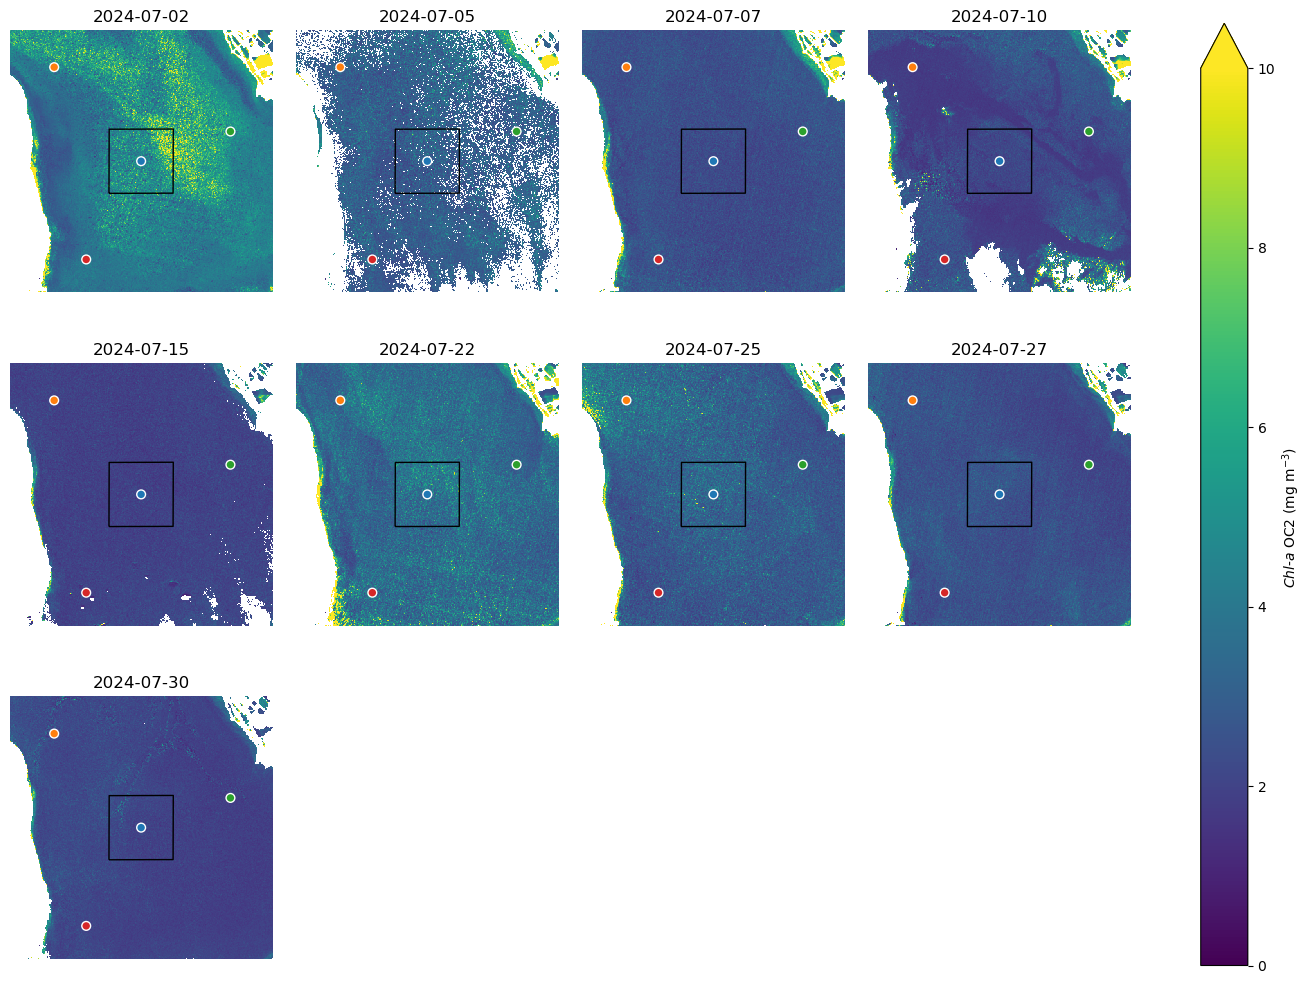

In [9]:
MONTH = '2024-07'
PARAM, VMIN, VMAX = 'Chla_OC2nasa', 0, 10


def add_geometries(ax):
    '''Draw the points and polygons of the viewer on a map in the CRS of the datacube.'''
    for index in range(n_poly):
        viewer.get_geom(crs=crs, index=index).boundary.plot(ax=ax, color='k', lw=1)
    if not points.empty:
        points.plot(ax=ax, color=points['color'], edgecolor='w', markersize=40)


g = wq[PARAM].sel(time=MONTH).plot.imshow(col='time', col_wrap=4, vmin=VMIN, vmax=VMAX, cmap='viridis',
                                          size=3.5, cbar_kwargs={'label': PARAMS.get(PARAM, PARAM)})
for ax, time in zip(g.axs.flat, wq.sel(time=MONTH).time.values):
    add_geometries(ax)
    ax.set_title(str(pd.Timestamp(time).date()))
    ax.set_aspect('equal')
    ax.set_axis_off()

### 4.2 Monthly composites

Median of the valid images of each month (pixels without any valid image in the month are left blank).

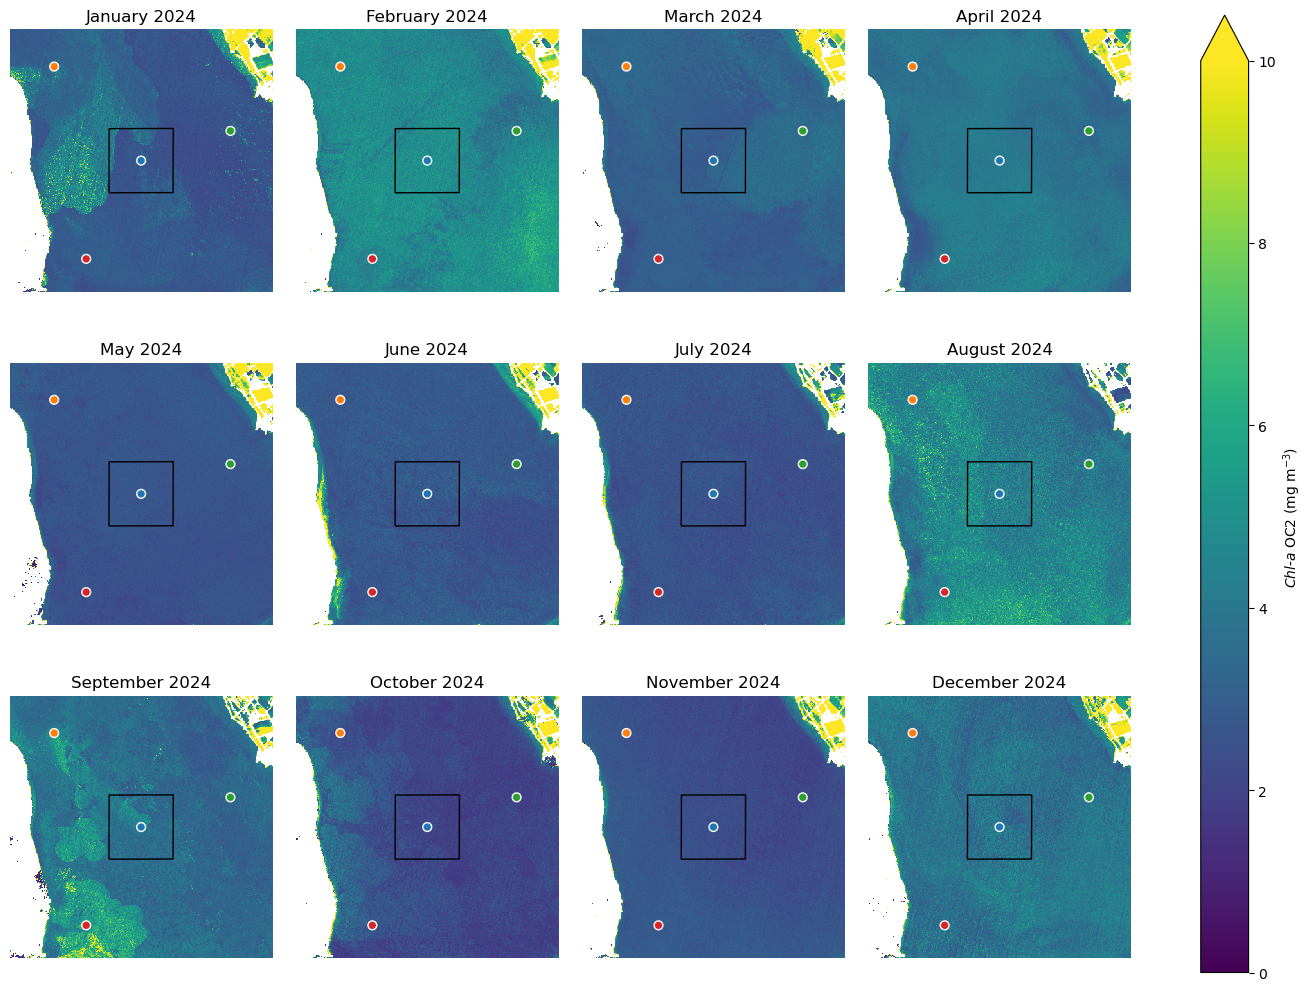

In [10]:
monthly = wq[PARAM].resample(time='MS').median()
g = monthly.plot.imshow(col='time', col_wrap=4, vmin=VMIN, vmax=VMAX, cmap='viridis', size=3.5,
                        cbar_kwargs={'label': PARAMS.get(PARAM, PARAM)})
for ax, time in zip(g.axs.flat, monthly.time.values):
    add_geometries(ax)
    ax.set_title(pd.Timestamp(time).strftime('%B %Y'))
    ax.set_aspect('equal')
    ax.set_axis_off()